# Predicción de cancelación de clientes en un gimnasio

**Proyecto de análisis de datos · TripleTen · 2026** · Angel Regino

**Objetivo:** entender por qué se van los clientes de una cadena de gimnasios, predecir quién está en riesgo de cancelar y agrupar a los clientes en perfiles para diseñar estrategias de retención.

**Datos:** 4 000 clientes con 13 características (contrato, edad, asistencia, gastos extra, etc.) y si cancelaron o no (`Churn`).


In [34]:
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Lasso, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import linkage, dendrogram

In [35]:
#CONOCIENDO LOS DATOS DEL GYMNACIO
gym_data = pd.read_csv("/datasets/gym_churn_us.csv") 
gym_data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 14 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   gender                             4000 non-null   int64  
 1   Near_Location                      4000 non-null   int64  
 2   Partner                            4000 non-null   int64  
 3   Promo_friends                      4000 non-null   int64  
 4   Phone                              4000 non-null   int64  
 5   Contract_period                    4000 non-null   int64  
 6   Group_visits                       4000 non-null   int64  
 7   Age                                4000 non-null   int64  
 8   Avg_additional_charges_total       4000 non-null   float64
 9   Month_to_end_contract              4000 non-null   float64
 10  Lifetime                           4000 non-null   int64  
 11  Avg_class_frequency_total          4000 non-null   float

In [36]:
#CONOCIENDO LOS DATOS
gym_data.describe()

,gender,Near_Location,Partner,Promo_friends,Phone,Contract_period,Group_visits,Age,Avg_additional_charges_total,Month_to_end_contract,Lifetime,Avg_class_frequency_total,Avg_class_frequency_current_month,Churn
count,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000
mean,0.510250,0.845250,0.486750,0.308500,0.903500,4.681250,0.412250,29.184250,146.943728,4.322750,3.724750,1.879020,1.767052,0.265250
std,0.499957,0.361711,0.499887,0.461932,0.295313,4.549706,0.492301,3.258367,96.355602,4.191297,3.749267,0.972245,1.052906,0.441521
min,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,18.000000,0.148205,1.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,1.000000,0.000000,0.000000,1.000000,1.000000,0.000000,27.000000,68.868830,1.000000,1.000000,1.180875,0.963003,0.000000
50%,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000,0.000000,29.000000,136.220159,1.000000,3.000000,1.832768,1.719574,0.000000
75%,1.000000,1.000000,1.000000,1.000000,1.000000,6.000000,1.000000,31.000000,210.949625,6.000000,5.000000,2.536078,2.510336,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,12.000000,1.000000,41.000000,552.590740,12.000000,31.000000,6.023668,6.146783,1.000000


In [37]:
agrupados_cancel = gym_data.groupby("Churn").mean()
print(agrupados_cancel)

         gender  Near_Location   Partner  Promo_friends     Phone  \
Churn                                                               
0      0.510037       0.873086  0.534195       0.353522  0.903709   
1      0.510839       0.768143  0.355325       0.183789  0.902922   

       Contract_period  Group_visits        Age  Avg_additional_charges_total  \
Churn                                                                           
0             5.747193      0.464103  29.976523                    158.445715   
1             1.728558      0.268615  26.989632                    115.082899   

       Month_to_end_contract  Lifetime  Avg_class_frequency_total  \
Churn                                                               
0                   5.283089  4.711807                   2.024876   
1                   1.662582  0.990575                   1.474995   

       Avg_class_frequency_current_month  
Churn                                     
0                               2.0

In [38]:
print(gym_data["Month_to_end_contract"].nunique())

12


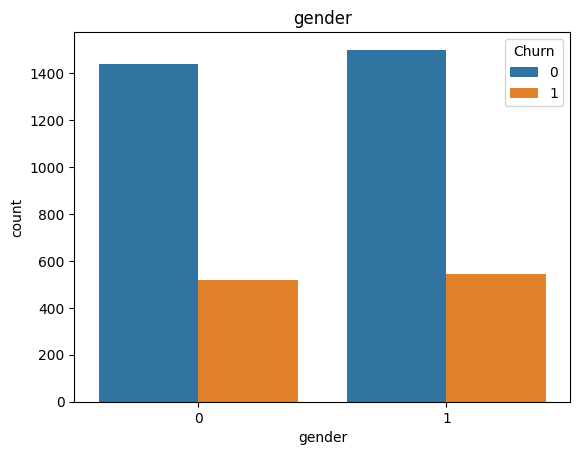

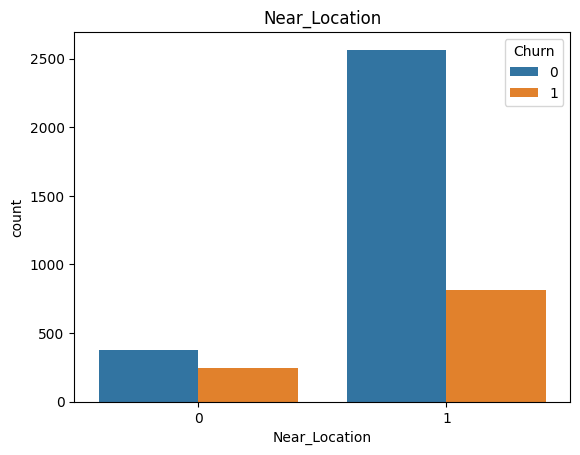

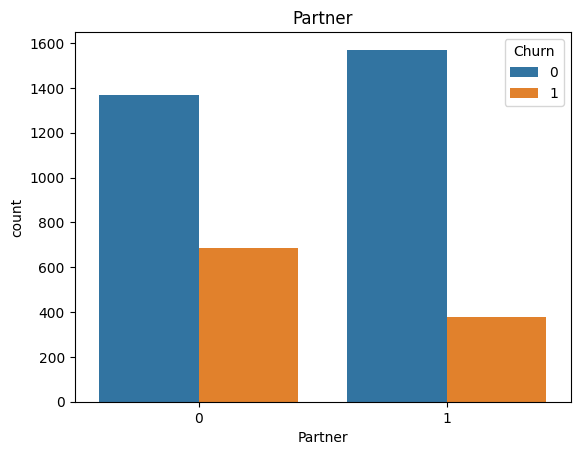

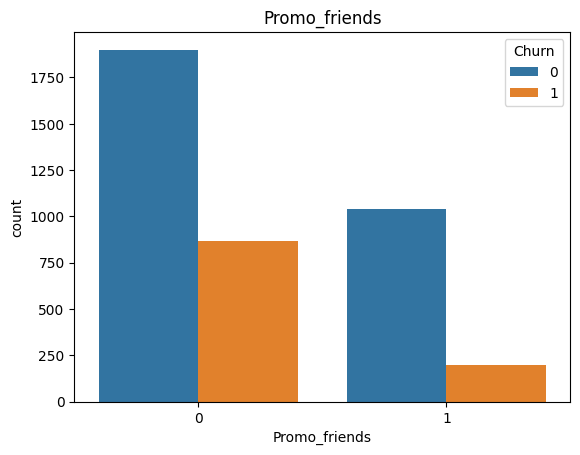

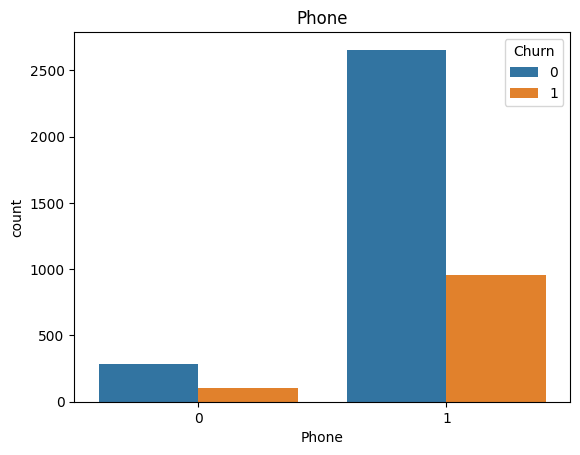

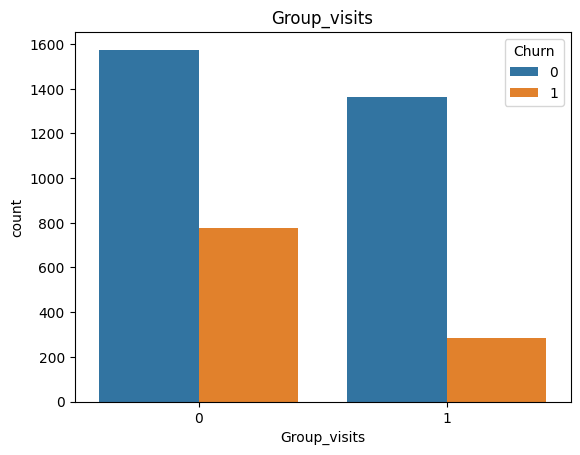

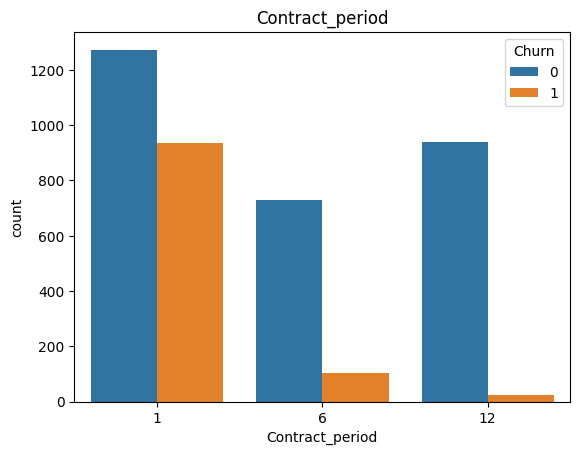

In [39]:
binary_cols = ["gender", "Near_Location", "Partner", "Promo_friends", "Phone", "Group_visits","Contract_period"]
for col in binary_cols:
    sns.countplot(x=col, hue="Churn", data= gym_data)
    plt.title(col)
    plt.show()
    


Variables binarias y categóricas (gráficos de barras)

Gender. La proporción de clientes que cancelan es prácticamente igual en ambos valores: la barra de cancelación equivale a cerca de un tercio de la de permanencia. El promedio por grupo (0.510 vs 0.511) lo confirma. Esta variable no permite distinguir a quienes se van de quienes se quedan.

Near_Location. Entre quienes viven o trabajan lejos del gimnasio, la cancelación es proporcionalmente más alta que entre quienes viven cerca. La diferencia es moderada (0.87 entre quienes se quedan vs 0.77 entre quienes se van), por lo que la cercanía favorece la permanencia, pero no es determinante.

Partner. Los clientes de empresas asociadas cancelan menos: la barra de cancelación es cerca de un cuarto de la de permanencia, frente a cerca de la mitad en quienes no pertenecen a una empresa asociada (0.53 vs 0.36). Los convenios con empresas parecen favorecer la retención.

Promo_friends. Quienes llegaron por la promoción “trae a un amigo” cancelan notablemente menos (0.35 vs 0.18). Es posible que acudir con alguien conocido aumente la motivación y el compromiso con el gimnasio.

Phone. La proporción de cancelación es casi idéntica con y sin teléfono registrado (0.904 vs 0.903). Esta variable no aporta para distinguir a los grupos.

Group_visits. Los clientes que participan en sesiones grupales cancelan menos (0.46 vs 0.27 de participación entre quienes se quedan y quienes se van). La actividad grupal parece generar un vínculo social que favorece la permanencia.

Contract_period. Es la variable que separa con más claridad a los grupos. Con contrato de 1 mes, la cancelación es muy alta (alrededor del 74% de la barra de permanencia). Con 6 meses baja a cerca del 14%, y con 12 meses es casi inexistente. El promedio es 5.75 meses entre quienes se quedan y 1.73 entre quienes se van. En los gráficos solo aparecen los periodos de 1, 6 y 12 meses. Si el de 3 meses existe, tiene tan pocos clientes que no se aprecia.



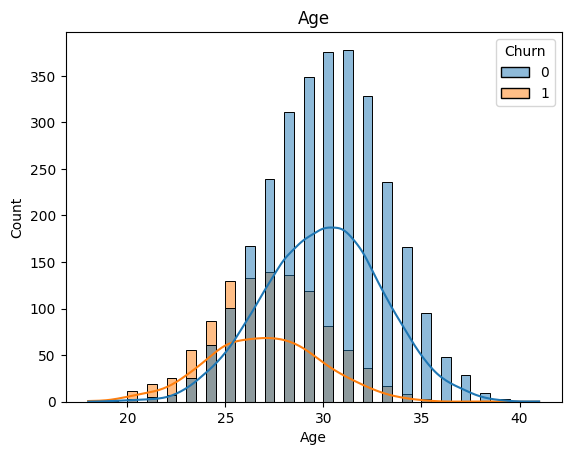

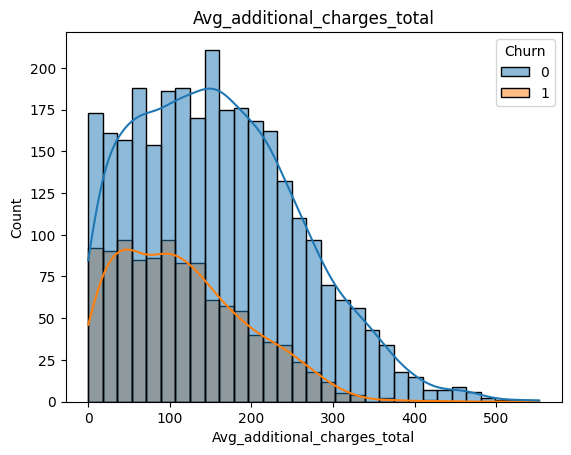

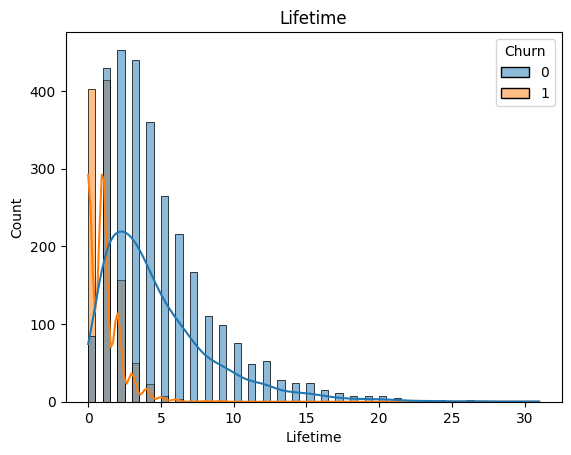

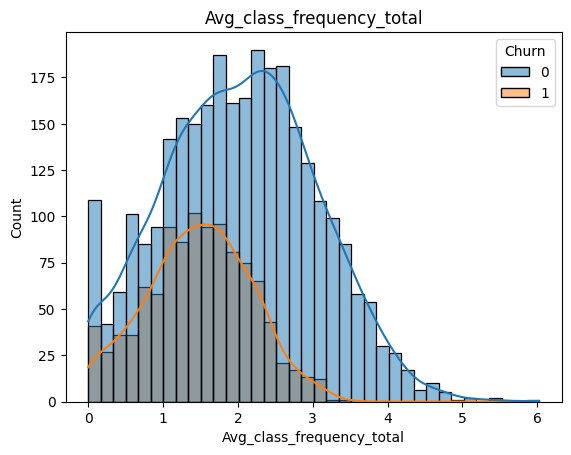

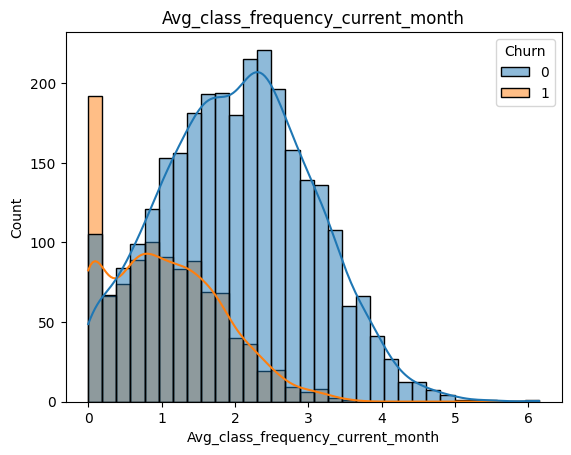

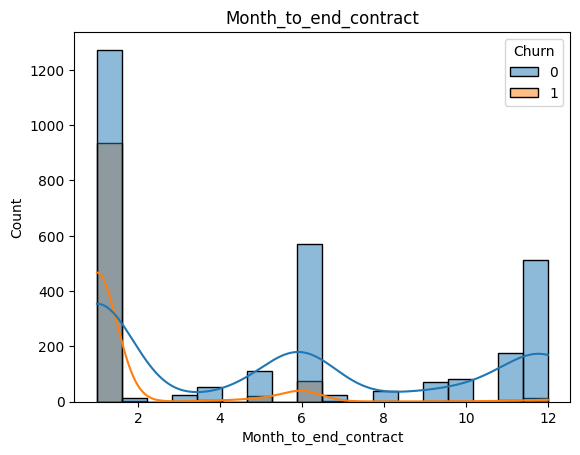

In [40]:
numeric_cols = ["Age","Avg_additional_charges_total","Lifetime","Avg_class_frequency_total","Avg_class_frequency_current_month","Month_to_end_contract"]   # tus nombres entre comillas

for col in numeric_cols:
    sns.histplot(data=gym_data, x=col, hue='Churn', kde=True)
    plt.title(col)
    plt.show()

Variables numéricas (histogramas)

Age. Los clientes que se van tienden a ser algo más jóvenes: el pico de su distribución está cerca de los 26-27 años, frente a los 30 de quienes se quedan (26.99 vs 29.98 de media). Como las distribuciones se traslapan bastante, la edad ayuda a distinguirlos solo de forma limitada.

Avg_additional_charges_total. Quienes cancelan gastan menos en servicios adicionales: su distribución se concentra entre 0 y 150 y casi desaparece después de 300, mientras que la de quienes se quedan llega hasta 500 (media de 158 vs 115). Un mayor gasto en servicios extra puede indicar un mayor involucramiento con el gimnasio.

Lifetime. La mayoría de las cancelaciones ocurre en los primeros meses: casi todos los clientes que se van tienen entre 0 y 2 meses de antigüedad (media de 0.99 contra 4.71). Esto indica que el riesgo se concentra al inicio de la relación con el gimnasio. Quien supera ese periodo tiene mucha menos probabilidad de irse.

Avg_class_frequency_total. Los clientes que cancelan asistían menos a lo largo de su historial, con un pico cercano a 1.5 visitas por semana frente a 2.3 de quienes se quedan (1.47 vs 2.02 en promedio). Las distribuciones se traslapan entre 1 y 3 visitas, por lo que la separación es moderada.

Avg_class_frequency_current_month. Es más reveladora que la frecuencia total. Los clientes que se van muestran una concentración muy alta en cero visitas durante el mes actual, y el resto se agrupa entre 0 y 2 visitas, mientras que quienes se quedan se concentran entre 1.5 y 3 (1.04 vs 2.03 en promedio). Una caída reciente en la asistencia funciona como señal temprana de cancelación.

Month_to_end_contract. Casi todos los clientes que cancelan tienen solo 1 mes restante de contrato, mientras que entre quienes tienen 6 o 12 meses por delante la cancelación es muy baja (1.66 vs 5.28 en promedio). Es lógico, pues el fin del contrato es el momento natural para no renovar. Esta variable se parece mucho a Contract_period, así que se espera que ambas estén fuertemente correlacionadas.

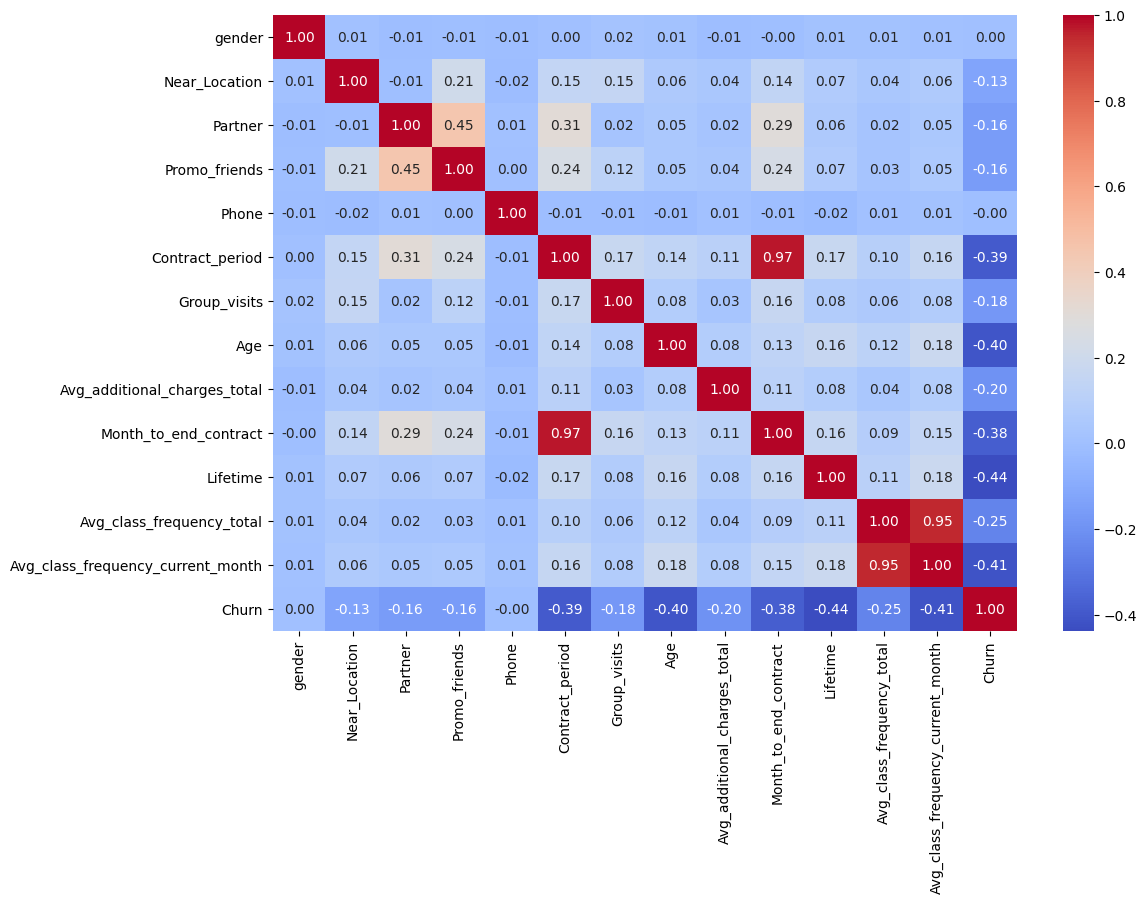

In [41]:
cm = gym_data.corr()
plt.figure(figsize=(12, 8))                # 2. tamaño grande: son 14 columnas
sns.heatmap(cm, annot=True, fmt='.2f', cmap='coolwarm')   # 3. dibuja; busca el parámetro de color
plt.show()

La matriz muestra que las variables más relacionadas con la cancelación son todas de correlación negativa: Lifetime (-0.44), Avg_class_frequency_current_month (-0.41), Age (-0.40), Contract_period (-0.39) y Month_to_end_contract (-0.38). Esto significa que los clientes con más antigüedad, mayor asistencia reciente, mayor edad y contratos más largos tienen menos probabilidad de cancelar. Ninguna correlación supera el -0.5, por lo que son relaciones moderadas: ninguna variable por sí sola explica la cancelación, y será la combinación de varias lo que permita al modelo predecirla.

Las variables gender (0.00) y Phone (0.00) no tienen relación con la cancelación, por lo que no ayudan a distinguir a quienes se van de quienes se quedan. Partner, Promo_friends, Group_visits y Near_Location muestran una relación débil (entre -0.13 y -0.18), aunque coherente con el EDA: pertenecer a una empresa asociada, llegar por un amigo o asistir a sesiones grupales favorece la permanencia.

Además, se detectó multicolinealidad en dos pares de variables: Contract_period con Month_to_end_contract (0.97) y Avg_class_frequency_total con Avg_class_frequency_current_month (0.95). Al aportar información casi idéntica, pueden generar inestabilidad en la regresión logística, por lo que conviene tenerlo presente al entrenar los modelos (por ejemplo, comparando resultados con y sin una variable de cada par).

In [42]:


#Paso 3. Construir un modelo para predecir la cancelación de usuarios
X= gym_data.drop(columns="Churn")
y= gym_data["Churn"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

scaler = StandardScaler()
X_train_st = scaler.fit_transform(X_train)

X_test_st = scaler.transform(X_test)

models= [LogisticRegression(random_state=0), RandomForestClassifier(random_state=0)]

for m in models:
    m.fit(X_train_st, y_train)
    predictions = m.predict(X_test_st)
    print(m)
    print('Accuracy: {:.2f}'.format(accuracy_score(y_test, predictions)))
    print('Precisión: {:.2f}'.format(precision_score(y_test, predictions)))
    print('Recall: {:.2f}'.format(recall_score(y_test, predictions)))

LogisticRegression(random_state=0)
Accuracy: 0.92
Precisión: 0.85
Recall: 0.83
RandomForestClassifier(random_state=0)
Accuracy: 0.92
Precisión: 0.84
Recall: 0.81


Ambos modelos clasifican correctamente al 92% de los clientes. Este resultado supera con claridad el 73% que se obtendría al predecir que nadie cancela, dado que cerca del 27% de los clientes se va. La precisión indica que, de los clientes que el modelo marca como en riesgo de cancelar, entre 84% y 85% realmente cancelan. El recall indica que el modelo detecta entre 81% y 83% de los clientes que efectivamente se van.

Conclusión. 
La regresión logística obtuvo mejores resultados que el bosque aleatorio, aunque por una diferencia pequeña (0.01 en precisión y 0.02 en recall). En la práctica, ambos modelos tienen un desempeño muy similar y detectan a más de 8 de cada 10 clientes que cancelan. Dado que la regresión logística es más simple y más fácil de interpretar, se considera la mejor opción para este caso. El gimnasio puede usar sus predicciones para identificar a los clientes en riesgo y acercarse a ellos antes de que cancelen.

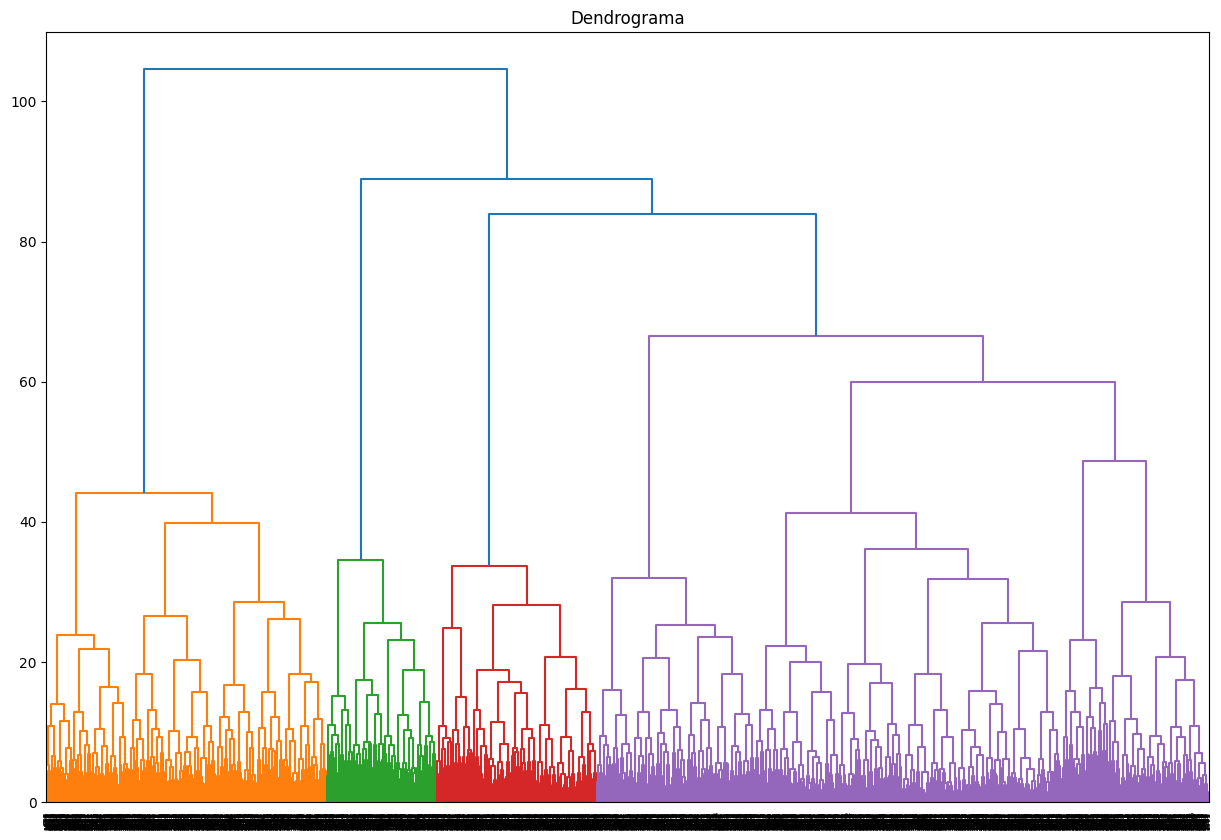

In [51]:
#Paso 4. Crear clústeres de usuarios/as

sc = StandardScaler()
X_cl = gym_data.drop(columns="Churn")
x_sc = sc.fit_transform(X_cl)
km= KMeans(n_clusters=5, random_state=0)
labels = km.fit_predict(x_sc)

linked = linkage(x_sc, method='ward')   

plt.figure(figsize=(15, 10))
dendrogram(linked, orientation='top')
plt.title('Dendrograma')
plt.show()

gym_data['cluster'] = labels


El dendrograma muestra varias ramas largas y bien diferenciadas antes de que los grupos se unan en uno solo. Al cortar el árbol a una altura cercana a 40, se cruzan entre 4 y 6 ramas principales. Si se corta mucho más abajo, aparecen cientos de grupos diminutos sin utilidad práctica, y si se corta mucho más arriba (cerca de 90), quedan solo 2 grupos demasiado generales.

Conclusión
El dendrograma sugiere entre 4 y 6 clústeres. Por indicación del proyecto, y para poder comparar resultados, se entrenó K-means con n = 5, valor que queda dentro de ese rango.

In [54]:
print(gym_data.columns)

Index(['gender', 'Near_Location', 'Partner', 'Promo_friends', 'Phone',
       'Contract_period', 'Group_visits', 'Age',
       'Avg_additional_charges_total', 'Month_to_end_contract', 'Lifetime',
       'Avg_class_frequency_total', 'Avg_class_frequency_current_month',
       'Churn', 'cluster'],
      dtype='object')


In [55]:
clusters_groups = gym_data.groupby('cluster').mean()
clusters_groups.T

cluster,0,1,2,3,4
gender,0.502970,0.522078,0.495050,0.485737,0.559666
Near_Location,0.959406,0.862338,0.000000,1.000000,0.976134
Partner,0.783168,0.470130,0.463366,0.350238,0.356802
Promo_friends,0.574257,0.306494,0.079208,0.240095,0.230310
Phone,1.000000,0.000000,1.000000,1.000000,0.998807
Contract_period,10.889109,4.787013,2.352475,1.948494,2.669451
Group_visits,0.542574,0.425974,0.215842,0.341521,0.473747
Age,29.982178,29.301299,28.477228,28.167987,30.125298
Avg_additional_charges_total,160.761016,143.957664,135.457501,131.622204,161.657905
Month_to_end_contract,9.954455,4.475325,2.198020,1.856577,2.459427


In [56]:
gym_data.groupby('cluster')['Churn'].mean().sort_values()

cluster
0    0.027723
4    0.068019
1    0.267532
2    0.443564
3    0.514263
Name: Churn, dtype: float64

Las tasas de cancelación difieren mucho entre clústeres: del 2.8% (clúster 0) al 51.4% (clúster 3). Los clústeres 0 y 4 son los más leales, caracterizados por contratos largos o alta asistencia. Los clústeres 2 y 3 son los más propensos a irse: el primero agrupa a clientes que viven lejos, y el segundo a clientes nuevos con contrato corto y baja asistencia.

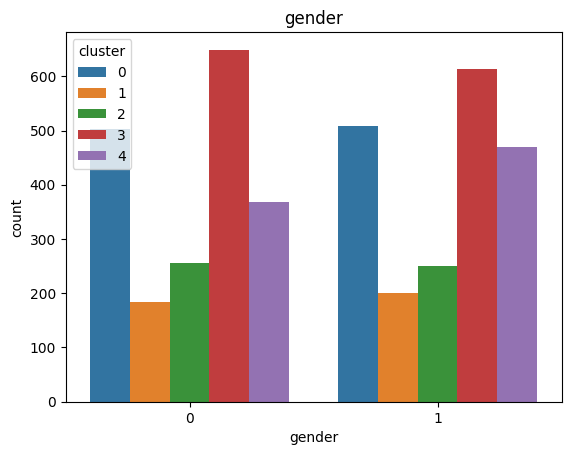

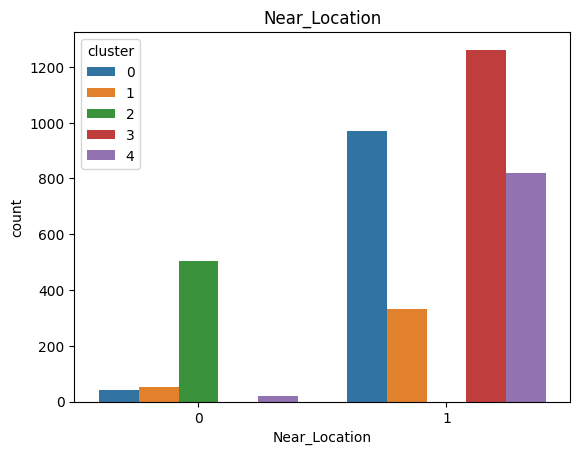

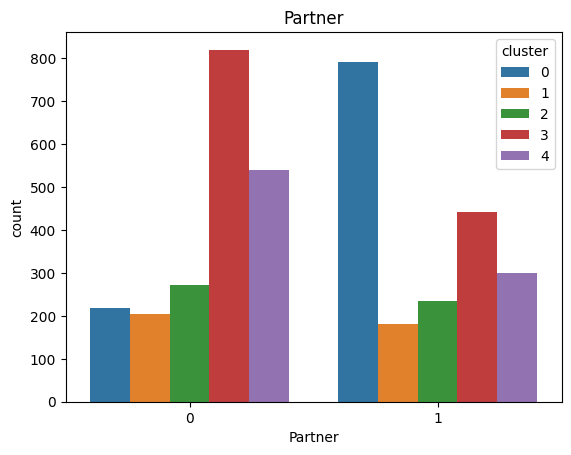

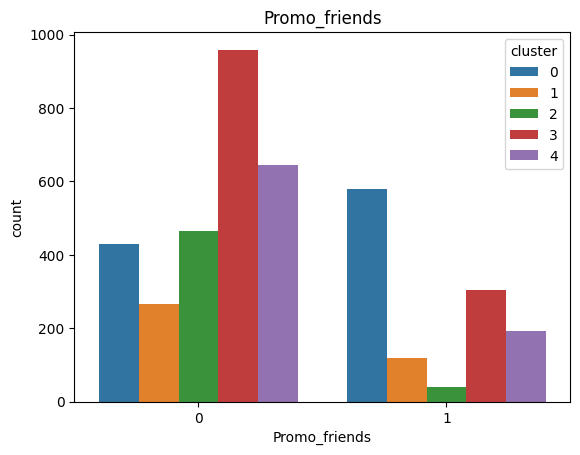

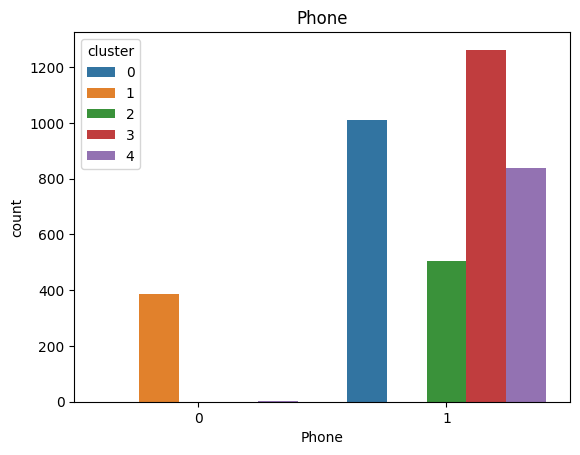

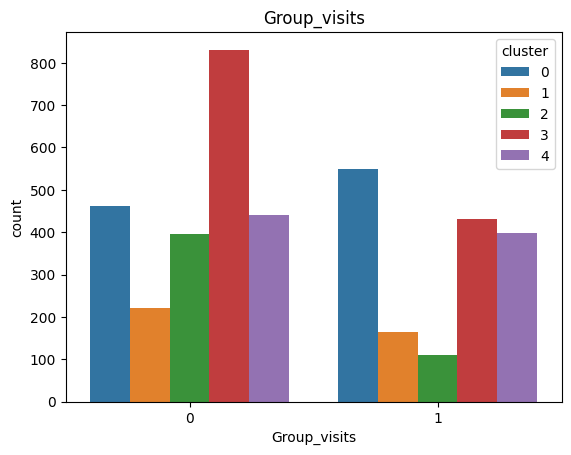

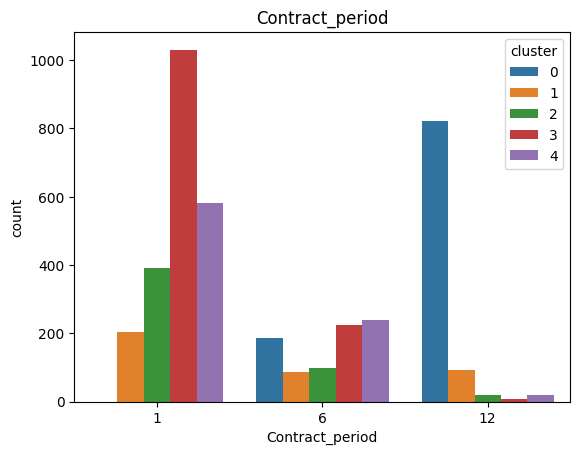

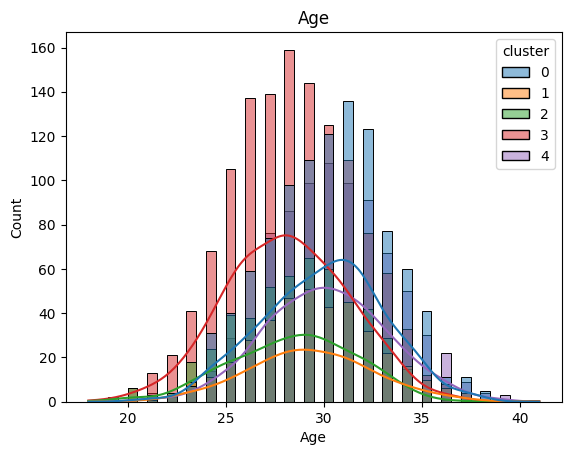

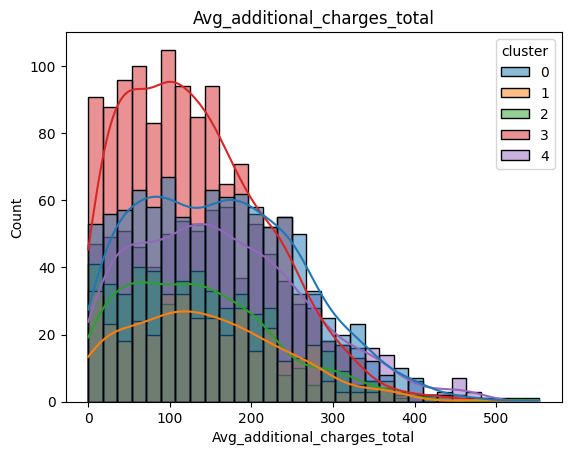

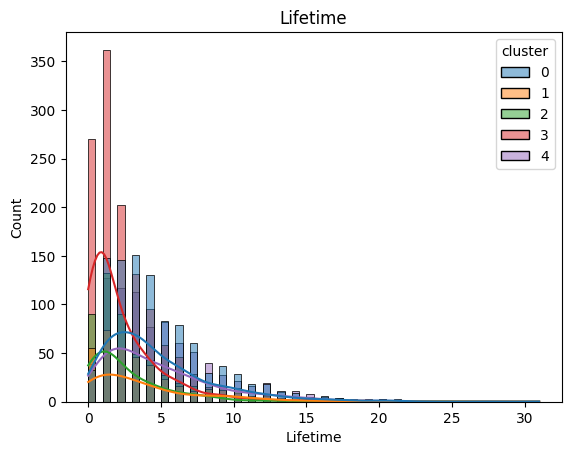

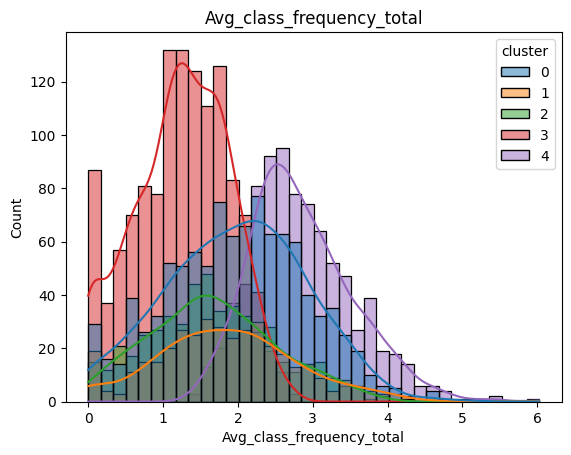

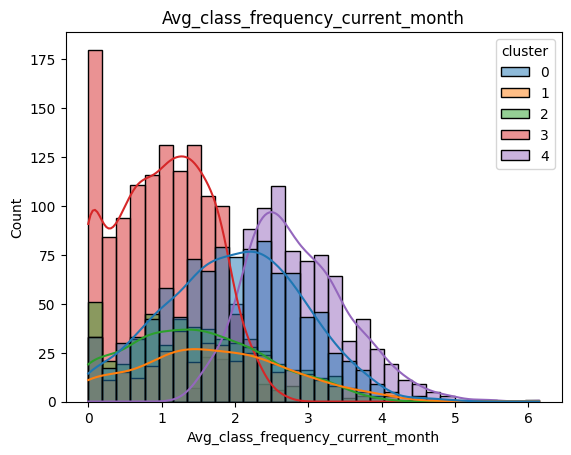

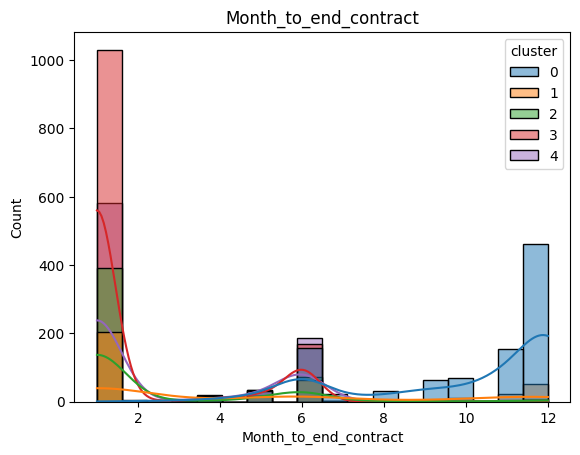

In [57]:
for col in binary_cols:
    sns.countplot(x=col, hue='cluster', data=gym_data, palette='tab10')
    plt.title(col)
    plt.show()

for col in numeric_cols:
    sns.histplot(data=gym_data, x=col, hue='cluster', kde=True, palette='tab10')
    plt.title(col)
    plt.show()

BARRAS
Las distribuciones por clúster confirman los perfiles de la tabla de promedios. El clúster 0 se distingue por contratos de 12 meses, pertenencia a empresas asociadas y llegada por amigos. El clúster 1 se define porque ninguno registró teléfono. El clúster 2 agrupa a quienes viven lejos del gimnasio, con poca participación en sesiones grupales y casi sin llegar por amigos. Los clústeres 3 y 4 se concentran en contratos de 1 mes. gender no diferencia a ningún grupo.

HISTOGRAMAS
Las distribuciones por clúster muestran que Age y Avg_additional_charges_total se traslapan en todos los grupos, por lo que no los diferencian. Las variables que sí separan a los clústeres son Lifetime, la frecuencia de visitas y los meses restantes de contrato. El clúster 3 concentra clientes nuevos (1 a 2 meses), con baja asistencia (en el mes actual, muchos con cero visitas) y con un solo mes de contrato restante. El clúster 4 se distingue por la mayor asistencia (2 a 3.5 visitas por semana), y el clúster 0 por contratos largos con muchos meses restantes.

Conclusiones

La cancelación no es aleatoria. Se concentra en clientes nuevos, con contrato corto y baja asistencia reciente. El EDA y la matriz de correlación lo confirman: las variables más ligadas a la permanencia son Lifetime (-0.44), Avg_class_frequency_current_month (-0.41), Contract_period (-0.39) y Month_to_end_contract (-0.38). gender y Phone no influyen.
Hay variables casi duplicadas. Contract_period con Month_to_end_contract (0.97) y las dos frecuencias de visitas (0.95) aportan información casi idéntica, algo a considerar al entrenar modelos.
Los modelos predicen bien la cancelación. Ambos alcanzaron una exactitud de 0.92. La regresión logística fue ligeramente mejor (precisión 0.85, recall 0.83) que el bosque aleatorio (0.84 y 0.81), y detecta a más de 8 de cada 10 clientes que se van.
Los clústeres confirman el patrón. El dendrograma sugirió entre 4 y 6 grupos; se usó K-means con n=5:

Recomendaciones

Fomentar la asistencia constante. Retos de visitas semanales con descuentos o servicios extra, y mensajes automáticos a quienes bajen su frecuencia (sobre todo a quienes llevan un mes sin venir).
Reforzar los primeros meses. Orientación gratuita, rutina guiada y seguimiento durante el primer y segundo mes, cuando más clientes se van (clúster 3).
Impulsar contratos más largos. Descuentos por pasar de 1 mes a 3 o 6 meses, porque los contratos largos casi no cancelan.
Aprovechar lo social. Reforzar la promoción “trae a un amigo”, los convenios con empresas y las sesiones grupales, sobre todo para el clúster 2 (quienes viven lejos), que casi no los usa.
Usar el modelo en la práctica. Aplicar la regresión logística cada mes para identificar a los clientes con mayor riesgo y dirigir primero a ellos estas acciones.